Discentes
*   Murilo Patricio Maia
*   Carlos Rafael González Alejo
*   Cainan Lima Neves
*   Pedro Herculano Zambo

# Dedução da Regra do Ponto Médio Composta


## 1. Particionamento do Intervalo
Seja $n$ um número par. O intervalo de integração $[a, b]$ é particionado em $n + 2$ subintervalos de comprimento $h$, tal que:$$h = \frac{b - a}{n + 2}$$Os nós da partição são definidos como $x_j = a + (j + 1)h$ para $j = -1, 0, 1, \dots, n + 1$, garantindo que $x_{-1} = a$ e $x_{n+1} = b$.

## 2. Decomposição da Integral
Pela propriedade aditiva das integrais definidas, a integral sobre o intervalo $[a, b]$ é expressa como o somatório das integrais sobre subintervalos de comprimento $2h$:$$\int_{a}^{b} f(x) \, dx = \sum_{j=0}^{n/2} \int_{x_{2j-1}}^{x_{2j+1}} f(x) \, dx$$

## 3. Aplicação da Regra Simples
Aplica-se a Regra do Ponto Médio Simples com seu respectivo termo de erro para cada subintervalo genérico $[x_{2j-1}, x_{2j+1}]$, onde $x_{2j}$ representa o ponto médio e $\xi_j \in (x_{2j-1}, x_{2j+1})$:$$\int_{x_{2j-1}}^{x_{2j+1}} f(x) \, dx = 2h f(x_{2j}) + \frac{h^3}{3} f''(\xi_j)$$Substituindo esta expressão no somatório da integral particionada:$$\int_{a}^{b} f(x) \, dx = \sum_{j=0}^{n/2} \left[ 2h f(x_{2j}) + \frac{h^3}{3} f''(\xi_j) \right]$$O que pode ser reescrito separando a aproximação e o termo de erro:$$\int_{a}^{b} f(x) \, dx = 2h \sum_{j=0}^{n/2} f(x_{2j}) + \frac{h^3}{3} \sum_{j=0}^{n/2} f''(\xi_j)$$

## 4. Avaliação do Termo de Erro Global
O termo de erro global $E$ da aproximação é:$$E = \frac{h^3}{3} \sum_{j=0}^{n/2} f''(\xi_j)$$O somatório de $j=0$ até $n/2$ compreende exatamente $\frac{n + 2}{2}$ termos. Assumindo $f \in C^2[a, b]$, aplica-se o Teorema do Valor Intermediário Generalizado, que permite representar a soma das derivadas segundas avaliadas nos pontos $\xi_j$ como um único ponto $\mu \in (a, b)$:$$\sum_{j=0}^{n/2} f''(\xi_j) = \frac{n + 2}{2} f''(\mu)$$Substituindo esta equivalência no termo de erro global:$$E = \frac{h^3}{3} \left( \frac{n + 2}{2} \right) f''(\mu)$$

## 5. Simplificação Final
A partir da definição do passo $h$ (estabelecida no item 1), isola-se o termo $(n + 2)$:$$n + 2 = \frac{b - a}{h}$$Substituindo esta relação na equação do erro global:$$E = \frac{h^3}{3} \left( \frac{b - a}{2h} \right) f''(\mu)$$Realizando a multiplicação geométrica e cancelando os termos em comum ($h$):$$E = \frac{b - a}{6} h^2 f''(\mu)$$Portanto, a representação exata da integral pela Regra do Ponto Médio Composta é:$$\int_{a}^{b} f(x) \, dx = 2h \sum_{j=0}^{n/2} f(x_{2j}) + \frac{b - a}{6} h^2 f''(\mu)$$

# Código do ponto médio composto

In [1]:
def ponto_medio_composto_com_erro(f, f_dupla_linha, a, b, n):
    """
    Aproxima a integral e calcula o limitante de erro usando a Regra do Ponto Médio Composta.

    Parâmetros:
    f (callable): A função a ser integrada.
    f_dupla_linha (callable): A segunda derivada da função f.
    a (float): Limite inferior.
    b (float): Limite superior.
    n (int): Parâmetro de discretização (par).

    Retorna:
    tuple: (área_aproximada, erro_maximo_estimado)
    """
    if n % 2 != 0:
        raise ValueError("O parâmetro 'n' deve ser um número par.")

    h = (b - a) / (n + 2)
    
    # 1. CÁLCULO DA INTEGRAL APROXIMADA
    soma_funcao = 0.0
    limite_somatorio = int(n / 2)

    for j in range(limite_somatorio + 1):
        x_2j = a + (2 * j + 1) * h
        soma_funcao += f(x_2j)

    area_aproximada = 2 * h * soma_funcao

    # 2. CÁLCULO DA COTA DE ERRO MÁXIMO
    pontos_amostragem = 1000
    passo_busca = (b - a) / pontos_amostragem
    max_derivada_segunda = 0.0
    
    for i in range(pontos_amostragem + 1):
        x_atual = a + i * passo_busca
        valor_absoluto_derivada = abs(f_dupla_linha(x_atual))
        
        if valor_absoluto_derivada > max_derivada_segunda:
            max_derivada_segunda = valor_absoluto_derivada
            
    erro_maximo = ((b - a) / 6.0) * (h ** 2) * max_derivada_segunda
    
    return area_aproximada, erro_maximo

# Exemplo de Teste e Validação

Vamos testar com a função $f(x) = e^{2x}$ no intervalo $[0, 1]$
* Integral exata: $\int_{0}^{1} e^{2x} \, dx = \left[ \frac{e^{2x}}{2} \right]_{0}^{1} = \frac{e^2 - 1}{2} \approx 3.194528049465$
* Segunda derivada: $f''(x) = 4e^{2x}$

In [2]:
import math

f = lambda x: math.exp(2 * x)
f_dupla_linha = lambda x: 4 * math.exp(2 * x)

# Limites de integração e parâmetro de discretização
a = 0.0
b = 1.0
n = 12  # Parâmetro n par para a malha de Burden

# --- EXECUÇÃO DO MÉTODO NUMÉRICO ---
area_numérica, erro_teorico_max = ponto_medio_composto_com_erro(f, f_dupla_linha, a, b, n)

# --- CÁLCULO DO VALOR ANALÍTICO (EXATO) ---
integral_exata = (math.exp(2) - 1) / 2
erro_real_cometido = abs(integral_exata - area_numérica)

# --- EXIBIÇÃO DOS RESULTADOS  ---
print("="*60)
print(f"Intervalo de integração:        [{a}, {b}]")
print(f"n utilizado:                    {n} (Gera {n+2} subintervalos)")
print(f"Passo h:                        {((b - a) / (n + 2)):.6f}")
print("-"*60)
print(f"Integral Exata (Analítica):     {integral_exata:.12f}")
print(f"Integral Obtida (Numérica):     {area_numérica:.12f}")
print("-"*60)
print(f"Erro Real:                      {erro_real_cometido:.12f}")
print(f"Cota de Erro Máximo Estimada:   {erro_teorico_max:.12f}")
print("="*60)

# Validação lógica do teorema
if erro_real_cometido <= erro_teorico_max:
    print("O erro real respeita o limite teórico.")
else:
    print("O erro real excedeu o limite teórico.")
print("="*60)

Intervalo de integração:        [0.0, 1.0]
n utilizado:                    12 (Gera 14 subintervalos)
Passo h:                        0.071429
------------------------------------------------------------
Integral Exata (Analítica):     3.194528049465
Integral Obtida (Numérica):     3.183688123059
------------------------------------------------------------
Erro Real:                      0.010839926406
Cota de Erro Máximo Estimada:   0.025132843874
O erro real respeita o limite teórico.


                ANÁLISE DE CONVERGÊNCIA: f(x) = e^(2x) no intervalo [{a}, {b}]                 
                               Integral Exata: 3.194528049465325                               
   n | Subint. (n+2) |    Passo h |     Aproximação |       Erro Real |  Erro Máx. Est.
-----------------------------------------------------------------------------------------------
   2 |             4 |   0.250000 |  3.065205170519 | 1.293228789462e-01 | 3.078773374554e-01
   4 |             6 |   0.166667 |  3.136128101338 | 5.839994812694e-02 | 1.368343722024e-01
   8 |            10 |   0.100000 |  3.173330163653 | 2.119788581186e-02 | 4.926037399287e-02
  16 |            18 |   0.055556 |  3.187964401606 | 6.563647858877e-03 | 1.520381913360e-02
  32 |            34 |   0.029412 |  3.192686504530 | 1.841544935379e-03 | 4.261278027065e-03
  64 |            66 |   0.015152 |  3.194039193352 | 4.888561136602e-04 | 1.130862580185e-03
 128 |           130 |   0.007692 |  3.194402036059 | 1.2601

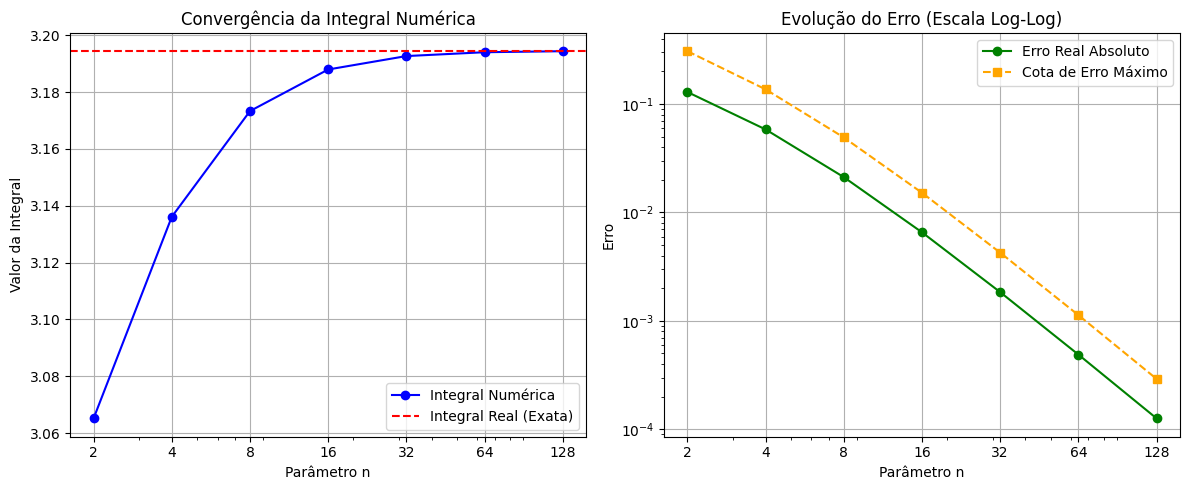

In [21]:
import numpy as np
import matplotlib.pyplot as plt

# Lista de valores pares para n
valores_n = [2, 4, 8, 16, 32, 64, 128]

historico_n = []
historico_aprox = []
historico_erro_real = []
historico_erro_max = []
    
# --- RESULTADOS ---
print("=" * 95)
print(f"{'ANÁLISE DE CONVERGÊNCIA: f(x) = e^(2x) no intervalo [{a}, {b}]':^95}")
print(f"{'Integral Exata: ' + str(integral_exata):^95}")
print("=" * 95)
print(f"{'n':>4} | {'Subint. (n+2)':>13} | {'Passo h':>10} | {'Aproximação':>15} | {'Erro Real':>15} | {'Erro Máx. Est.':>15}")
print("-" * 95)

for n in valores_n:
    h = (b - a) / (n + 2)
    area_numérica, erro_teorico_max = ponto_medio_composto_com_erro(f, f_dupla_linha, a, b, n)
    erro_real = abs(integral_exata - area_numérica)
    
    print(f"{n:>4} | {n+2:>13} | {h:>10.6f} | {area_numérica:>15.12f} | {erro_real:>15.12e} | {erro_teorico_max:>15.12e}")
    
    historico_n.append(n)
    historico_aprox.append(area_numérica)
    historico_erro_real.append(erro_real)
    historico_erro_max.append(erro_teorico_max)

print("=" * 95)

# --- GRÁFICOS ---
fig, ax = plt.subplots(1, 2, figsize=(12, 5), sharex=True)

# Gráfico 1
ax[0].plot(historico_n, historico_aprox, 'o-', color='blue', label='Integral Numérica')
ax[0].axhline(y=integral_exata, color='red', linestyle='--', label='Integral Real (Exata)')
ax[0].set_title('Convergência da Integral Numérica')
ax[0].set_xlabel('Parâmetro n')
ax[0].set_ylabel('Valor da Integral')
ax[0].grid(True)
ax[0].legend()

# Gráfico 2
ax[1].loglog(historico_n, historico_erro_real, 'o-', color='green', label='Erro Real Absoluto')
ax[1].loglog(historico_n, historico_erro_max, 's--', color='orange', label='Cota de Erro Máximo')
ax[1].set_title('Evolução do Erro (Escala Log-Log)')
ax[1].set_xlabel('Parâmetro n')
ax[1].set_ylabel('Erro')
ax[1].grid(True)
ax[1].legend()

ax[0].set_xticks(valores_n)
ax[0].set_xticklabels([str(n) for n in valores_n])

plt.tight_layout()
plt.show()

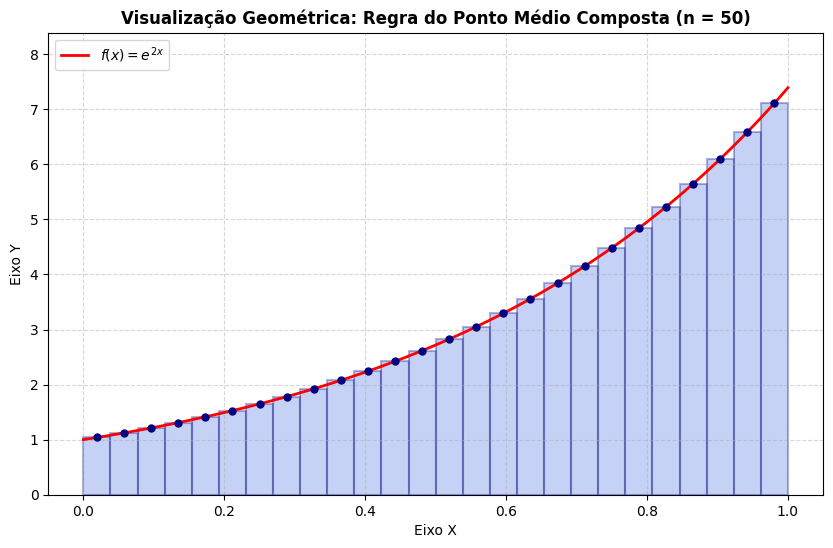

In [6]:


def plotar_ponto_medio_composto(a, b, n):
    if n % 2 != 0:
        raise ValueError("O parâmetro 'n' deve ser um número par.")
    
    f = lambda x: np.exp(2 * x)
    h = (b - a) / (n + 2)
    limite_somatorio = int(n / 2)

    x_curva = np.linspace(a, b, 500)
    y_curva = f(x_curva)

    plt.figure(figsize=(10, 6))
    plt.plot(x_curva, y_curva, color='red', linewidth=2, label=r'$f(x) = e^{2x}$')

    for j in range(limite_somatorio + 1):
        x_esquerdo = a + (2 * j) * h
        x_medio = a + (2 * j + 1) * h
        altura = f(x_medio)

        plt.bar(x_esquerdo, altura, width=2*h, align='edge', 
                alpha=0.3, color='royalblue', edgecolor='navy', linewidth=1.5)
        
        plt.plot(x_medio, altura, marker='o', color='navy', markersize=5)

    plt.title(f'Visualização Geométrica: Regra do Ponto Médio Composta (n = {n})', fontsize=12, fontweight='bold')
    plt.xlabel('Eixo X', fontsize=10)
    plt.ylabel('Eixo Y', fontsize=10)
    plt.xlim(a - 0.05, b + 0.05)
    plt.ylim(0, f(b) + 1)
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.legend(loc='upper left')
    plt.show()

if __name__ == "__main__":
    limite_inferior = 0.0
    limite_superior = 1.0
    parametro_n = 50  
    
    plotar_ponto_medio_composto(limite_inferior, limite_superior, parametro_n)

Com base nos resultados numéricos e nas simulações gráficas obtidas, conclui-se que o aumento do parâmetro de discretização $n$ promove uma redução contínua e previsível do erro de aproximação.

Do ponto de vista geométrico, o refinamento da malha (redução do passo $h$) faz com que a largura dos retângulos diminua, permitindo que eles se ajustem com maior precisão à curvatura da função $f(x)$. Esse processo minimiza significativamente as áreas vazias de subestimação e os excessos de superestimação, fazendo com que o somatório das áreas discretas dos retângulos convirja para a área sob a curva da integral definida.